In [63]:
# import some library
import pandas as pd
import numpy as np

In [64]:
df = pd.read_csv("powerplant_data.csv")

df.head()

,AT,V,AP,RH,PE
0,8.34,40.77,1010.84,90.01,480.48
1,23.64,58.49,1011.40,74.20,445.75
2,29.74,56.90,1007.15,41.91,438.76
3,19.07,49.69,1007.22,76.79,453.09
4,11.80,40.66,1017.13,97.20,464.43


In [65]:
df.isnull().sum()

AT    0
V     0
AP    0
RH    0
PE    0
dtype: int64

In [66]:
# AT => temperature
# V => vacuum
# AP => pressure
# RH => humidity

# PE => produced energy

In [67]:
X = df.drop("PE", axis=1)
y = df["PE"]

In [68]:
# Convertiing dataset into tensor

# 1. split the dataset
from sklearn.model_selection import train_test_split

X_train , X_test , y_train , y_test = train_test_split(
    X , y , test_size=0.2 , random_state=42
)

In [69]:
# 2. Apply standardscaler
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [70]:
# Convert into tensor
import torch
import torch.nn as nn

X_train_tensor = torch.tensor(X_train_scaled , dtype=torch.float32)
y_train_tensor = torch.tensor(y_train.values , dtype=torch.float32).view(-1,1)

X_test_tensor = torch.tensor(X_test_scaled , dtype=torch.float32)
y_test_tensor = torch.tensor(y_test.values , dtype=torch.float32).view(-1,1)

In [71]:
# using tensor datset load in Dataloder for baching
from torch.utils.data import TensorDataset, DataLoader

train_dataset = TensorDataset(X_train_tensor , y_train_tensor )
test_dataset = TensorDataset(X_test_tensor , y_test_tensor)

In [72]:
# use dataloader add bach

train_loader = DataLoader(train_dataset , batch_size=32 , shuffle=True)
test_loader = DataLoader(test_dataset , batch_size=32)

# Build ANN Model

In [73]:
# Deep Learning
class ANN(nn.Module):
    def __init__(self):
        super(ANN , self).__init__()

        self.model = nn.Sequential(

            # 1 Hidden layer
            nn.Linear(X_train.shape[1], 6),
            nn.ReLU(),

            # 2 Hidden Layer 
            nn.Linear(6, 6),
            nn.ReLU(),

            # Output Layer
            nn.Linear(6, 1),
        )

    def forward(self , x):
        return self.model(x)

In [74]:
# Build Actual Model
import torch.optim as optim
model = ANN()

# Losss & Optimzer 
crietrion = nn.MSELoss()
optimizer = optim.Adam(model.parameters())


In [75]:
# Train Our Ann
train_losses = []
val_losses = []
best_val_loss = float("inf")
epochs = 50

for epoch in range(epochs):
    model.train()
    running_loss = 0.0 # Total runn loss for epoch
    for xb , yb in train_loader:
        # xb ==> feature of one batches 
        # yb ==> labels of on batch
        optimizer.zero_grad()

        outputs = model(xb) # forward Prop>>> predict output for this
        loss = crietrion(outputs , yb) # computr loss
        loss.backward() # back....propogation compute gradient
        optimizer.step() # param update

        running_loss += loss.item() # loss is tensor to ==> py float

    epoch_train_loss = running_loss / len(train_loader)
    train_losses.append(epoch_train_loss)

    # Viladition in looop epochs 
    model.eval()
    running_val_loss = 0.0

    with torch.no_grad(): #no gradient compute
        for xb , yb in test_loader:
            outputs = model(xb)
            loss = crietrion(outputs , yb)
            running_val_loss += loss

    epoch_val_loss = running_val_loss / len(test_loader)
    val_losses.append(epoch_val_loss)

    print(f"epoch{epoch+1} / {epochs} ==> training loss = {epoch_train_loss} & loss {running_val_loss} ")

    # Put the value in best val loss
    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        torch.save(model.state_dict() , "best_model.pt")
    

epoch1 / 50 ==> training loss = 206485.36315104167 & loss 12291561.0 
epoch2 / 50 ==> training loss = 195694.82701822917 & loss 10748509.0 
epoch3 / 50 ==> training loss = 149591.82376302083 & loss 6958778.5 
epoch4 / 50 ==> training loss = 83428.30143229167 & loss 3333563.75 
epoch5 / 50 ==> training loss = 39703.44002278646 & loss 1681123.0 
epoch6 / 50 ==> training loss = 22665.29572347005 & loss 1082082.25 
epoch7 / 50 ==> training loss = 15861.60341796875 & loss 802493.1875 
epoch8 / 50 ==> training loss = 11993.470231119793 & loss 600143.9375 
epoch9 / 50 ==> training loss = 8752.51787109375 & loss 426968.59375 
epoch10 / 50 ==> training loss = 6093.879026285807 & loss 289073.5 
epoch11 / 50 ==> training loss = 4103.15893351237 & loss 191663.03125 
epoch12 / 50 ==> training loss = 2771.746102396647 & loss 129348.421875 
epoch13 / 50 ==> training loss = 1889.8020940144856 & loss 88907.734375 
epoch14 / 50 ==> training loss = 1325.3289377848307 & loss 62528.15625 
epoch15 / 50 ==> 

In [76]:
# Loding the best model
model.load_state_dict(torch.load("best_model.pt"))

<All keys matched successfully>

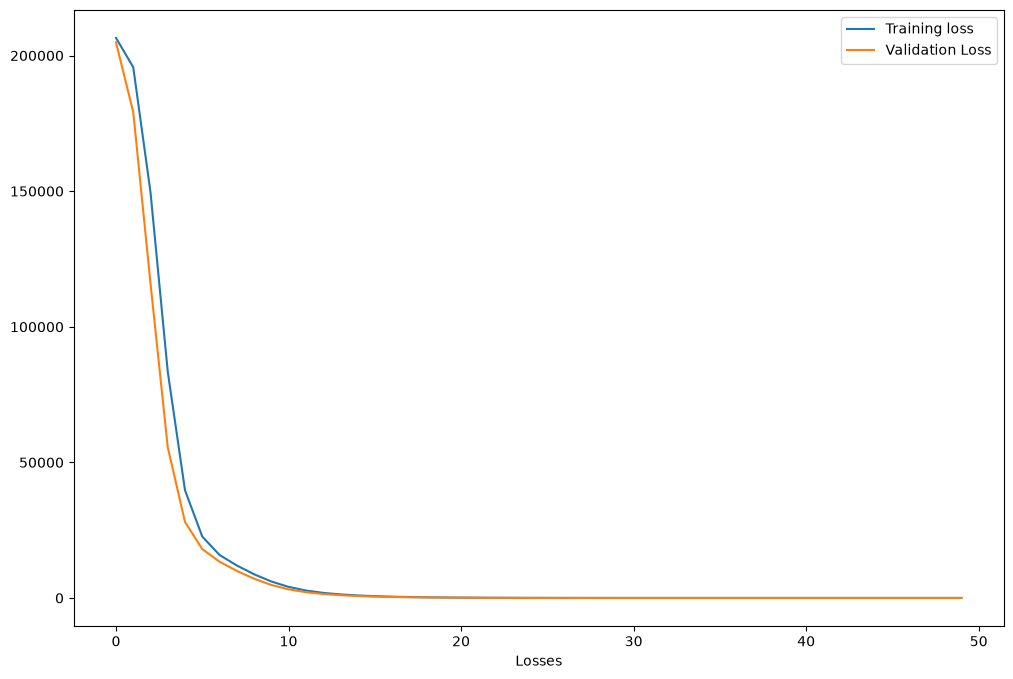

In [77]:
# Plot the model 
import matplotlib.pyplot as plt
loss_df = pd.DataFrame({
    "Training Loss" : train_losses,
    "Validation Loss" : val_losses
})
plt.figure(figsize=(12,8))
plt.plot(loss_df["Training Loss"] , label="Training loss")
plt.plot(loss_df["Validation Loss"] , label="Validation Loss")

plt.xlabel("Epoch")
plt.xlabel("Losses")
plt.legend()

In [80]:
# Evalute our model 
model.eval()
with torch.no_grad():
    train_preds = model(X_train_tensor)
    test_preds = model(X_test_tensor)

    # MSE Calcluate
    train_mse_loss = crietrion(train_preds , y_train_tensor)
    test_mse_loss = crietrion(test_preds , y_test_tensor)

print("Training MSE :", train_mse_loss.item())
print("Testing MSE :", test_mse_loss.item())

Training MSE : 20.998830795288086
Testing MSE : 19.06414031982422


In [86]:
# Check r2 Score 
from sklearn.metrics import r2_score
print("r2 Score :" , r2_score(y_test , test_preds))

r2 Score : 0.9333757501612797


In [89]:
# Check predict value
predict_df = pd.DataFrame(test_preds.numpy() , columns=["Predicted Value"])
actual_df = pd.DataFrame(y_test.values , columns=["Actual value"])

pd.concat([predict_df ,actual_df ] , axis=1)

,Predicted Value,Actual value
0,434.859589,433.27
1,436.494568,438.16
2,461.391418,458.42
3,476.442322,480.82
4,435.098663,441.41
...,...,...
1909,451.078674,456.70
1910,431.184784,438.04
1911,467.484009,467.80
1912,430.611511,437.14
